# Exercise 3 — Audio Steganography (CM3065)

This notebook completes **Exercise 3** using Python:

- **Task 3.1:** Detect which suspicious audio file contains a hidden **4-digit code** shifted into an **ultrasonic band** using **amplitude modulation (AM)**, then recover it into the audible range for listening.
- **Task 3.2:** Embed the required secret message into `Ex3_sound5.wav` using an enhanced LSB method, then extract it back and verify it matches exactly:

> It always seems impossible until it's done

All outputs are saved into an `outputs/` folder for repeatable marking and clear evidence screenshots.


In [2]:

# ------------------------------------------------------------
# Importing libraries 
# ------------------------------------------------------------
import os
import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

import librosa
import librosa.display

# ------------------------------------------------------------
# Directory setup
# ------------------------------------------------------------

# Sets the working audio directory to the current folder, where the Ex3 WAV files are expected to be located.
AUDIO_DIR = "."          # current folder contains Ex3_sound1..5.wav

# Defines an output folder name for any generated plots, processed audio, or intermediate artifacts.
OUT_DIR = "outputs"

# Creates the output folder if it does not already exist, avoiding errors when saving files later.
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Input file lists
# ------------------------------------------------------------

# Builds a list of WAV file paths that will be treated as “suspicious” signals for analysis/processing.
# These are the files that typically contain the hidden/encoded content in this exercise.
SUSPICIOUS = [
    os.path.join(AUDIO_DIR, "Ex3_sound1.wav"),
    os.path.join(AUDIO_DIR, "Ex3_sound2.wav"),
    os.path.join(AUDIO_DIR, "Ex3_sound3.wav"),
    os.path.join(AUDIO_DIR, "Ex3_sound4.wav"),
]

# Defines the file path for the carrier/reference audio signal (commonly used for comparison or mixing).
CARRIER_WAV = os.path.join(AUDIO_DIR, "Ex3_sound5.wav")

# ------------------------------------------------------------
# File presence validation
# ------------------------------------------------------------

# Iterates through every required file path and confirms it exists on disk before continuing.
# This prevents later DSP steps from failing due to missing inputs.
for p in SUSPICIOUS + [CARRIER_WAV]:
    if not os.path.isfile(p):
        raise FileNotFoundError(f"Missing audio file: {p}")

# Prints a confirmation once all expected audio files are detected.
print(" All Ex3 audio files found.")

# ------------------------------------------------------------
# Signal processing parameters
# ------------------------------------------------------------

# Defines the lower bound of the ultrasonic band of interest (Hz) for extracting or analyzing hidden energy.
ULTRASONIC_LO = 18000

# Defines the upper bound of the ultrasonic band of interest (Hz).
ULTRASONIC_HI = 24000

# Sets the FFT window size used for spectral analysis and spectrogram computations.
# Larger values provide finer frequency resolution at the cost of time resolution.
N_FFT = 4096

# Sets the hop length (step size) between FFT windows.
# Smaller hop values increase time resolution and smoothness but cost more compute.
HOP = 512



 All Ex3 audio files found.


## Working directory and expected files

This notebook assumes it is run inside the **Ex3_files** folder containing:

- `Ex3_sound1.wav` … `Ex3_sound4.wav` (suspicious set)
- `Ex3_sound5.wav` (carrier file for Task 3.2)

Generated results are written to:

- `outputs/`

A file existence check is used so missing WAV files are detected early with a clear error message.


## 3.1A — Scan suspicious files and rank anomalies

Each suspicious audio file is analysed to compute:

- **Ultrasonic-band energy** (average power-like measure from STFT magnitudes)
- **Dominant ultrasonic peak frequency** (a carrier candidate)

The files are ranked from highest to lowest ultrasonic energy. The highest-energy file is selected as the best candidate for demodulation.



In [5]:
# ============================================================
# Task 3.1 — Ultrasonic detection + AM demodulation to audible
# ============================================================

def load_mono(path, target_sr=None):
    # Loads an audio file as a single (mono) channel to simplify analysis and avoid channel mismatch issues.
    # Uses librosa’s resampling if target_sr is provided; otherwise preserves the original sample rate.
    # Produces a float32 waveform normalized to approximately [-1, 1] with its corresponding sample rate.
    y, sr = librosa.load(path, sr=target_sr, mono=True, dtype=np.float32)
    return y, sr

def band_energy_from_stft(y, sr, f_lo, f_hi, n_fft=4096, hop=512):
    # Computes the Short-Time Fourier Transform (STFT) so frequency content can be inspected over time.
    # Magnitude is used because energy comparisons rely on amplitude rather than complex phase values.
    S = librosa.stft(y, n_fft=n_fft, hop_length=hop, window="hann", center=True)
    S_mag = np.abs(S)

    # Builds a frequency axis (Hz) for FFT bins and a time axis (seconds) for frame positions.
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    times = librosa.frames_to_time(np.arange(S_mag.shape[1]), sr=sr, hop_length=hop)

    # Clamps the high cutoff so the band never exceeds the Nyquist limit for the current sample rate.
    # This avoids selecting invalid bins when the audio sample rate is lower than expected.
    f_hi_eff = min(f_hi, sr/2 - 1.0)

    # Selects the STFT rows whose frequencies fall inside the requested ultrasonic band.
    idx = np.where((freqs >= f_lo) & (freqs <= f_hi_eff))[0]

    # If the band does not exist at this sample rate (e.g., Nyquist too low), returns zero energy safely.
    if idx.size == 0:
        return 0.0, freqs, times, S_mag

    # Extracts only the magnitudes within the target band across all time frames.
    band_mag = S_mag[idx, :]

    # Converts magnitude to a simple power-like measure by squaring, then averages over time and bins.
    # Higher values indicate more ultrasonic activity concentrated in the specified range.
    band_energy = float(np.mean(band_mag**2))
    return band_energy, freqs, times, S_mag

def estimate_ultrasonic_peak_freq(y, sr, f_lo, f_hi, n_fft=4096, hop=512):
    # Computes an STFT for the same reason as above: find frequency structure over time.
    # The goal here is to identify the strongest single frequency component within the ultrasonic region.
    S = librosa.stft(y, n_fft=n_fft, hop_length=hop, window="hann", center=True)
    S_mag = np.abs(S)
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)

    # Ensures the upper band edge stays within the representable frequency range (below Nyquist).
    f_hi_eff = min(f_hi, sr/2 - 1.0)

    # Identifies FFT bins that fall inside the target ultrasonic window.
    idx = np.where((freqs >= f_lo) & (freqs <= f_hi_eff))[0]

    # If there are no bins in that band, there is no meaningful ultrasonic peak to estimate.
    if idx.size == 0:
        return None

    # Averages the magnitude spectrum over time to obtain a stable “typical” spectrum for the band.
    avg_spec = np.mean(S_mag[idx, :], axis=1)

    # Finds the bin with the maximum average magnitude and maps that bin back to its frequency in Hz.
    peak_bin = idx[int(np.argmax(avg_spec))]
    return float(freqs[peak_bin])

def butter_bandpass(sr, lo, hi, order=6):
    # Computes Nyquist frequency for normalized digital filter design.
    nyq = sr / 2

    # Forces the lower cutoff above 0 Hz to avoid invalid filter definitions.
    lo = max(1.0, lo)

    # Forces the upper cutoff below Nyquist to keep filter design stable and valid.
    hi = min(hi, nyq - 1.0)

    # Designs a Butterworth bandpass filter and returns numerator/denominator coefficients.
    b, a = signal.butter(order, [lo/nyq, hi/nyq], btype="bandpass")
    return b, a

def butter_lowpass(sr, cutoff, order=6):
    # Computes Nyquist frequency for normalized cutoff conversion.
    nyq = sr / 2

    # Ensures the cutoff remains below Nyquist so the low-pass filter can be designed correctly.
    cutoff = min(cutoff, nyq - 1.0)

    # Designs a Butterworth low-pass filter and returns numerator/denominator coefficients.
    b, a = signal.butter(order, cutoff/nyq, btype="lowpass")
    return b, a

def am_demod_to_audible(y, sr, carrier_hz, bp_width=2500, audible_lp=4500):
    # Demodulates a presumed AM-encoded message centered around a known/estimated carrier frequency.
    # The pipeline isolates the carrier band, mixes it down to baseband, then low-passes to keep audio-range content.

    # Defines a bandpass window around the carrier so unrelated frequencies do not affect demodulation.
    lo = carrier_hz - bp_width/2
    hi = carrier_hz + bp_width/2

    # Applies the bandpass filter using zero-phase filtering to prevent phase distortion and alignment shifts.
    b_bp, a_bp = butter_bandpass(sr, lo, hi, order=6)
    y_bp = signal.filtfilt(b_bp, a_bp, y).astype(np.float32)

    # Builds a time axis so a cosine oscillator can be generated at exactly the carrier frequency.
    t = np.arange(len(y_bp), dtype=np.float32) / sr

    # Generates a cosine at the carrier frequency to shift the band down to around 0 Hz (heterodyning).
    mixer = np.cos(2*np.pi*carrier_hz*t).astype(np.float32)

    # Multiplies the bandpassed signal by the oscillator to translate the spectrum down to baseband.
    y_mix = y_bp * mixer

    # Low-pass filtering removes high-frequency mixing products and keeps only the audible-range message content.
    b_lp, a_lp = butter_lowpass(sr, audible_lp, order=6)
    y_lp = signal.filtfilt(b_lp, a_lp, y_mix).astype(np.float32)

    # Normalizes the output waveform so it plays back cleanly without clipping while keeping strong amplitude.
    maxv = np.max(np.abs(y_lp)) + 1e-9
    return (0.95 * y_lp / maxv).astype(np.float32)

def save_wav_int16(path, y_float, sr):
    # Clips the floating waveform to the legal range for audio signals before integer conversion.
    y_clip = np.clip(y_float, -1.0, 1.0)

    # Converts normalized float samples into signed 16-bit PCM, which is widely supported for WAV storage.
    y_i16 = (y_clip * 32767.0).astype(np.int16)

    # Writes the WAV file to disk at the specified sample rate.
    wavfile.write(path, sr, y_i16)

# -------------------------
# 3.1A) Scan all suspicious files for ultrasonic-band anomalies
# -------------------------

# Holds per-file analysis results so files can be compared and ranked consistently.
results = []

for p in SUSPICIOUS:
    # Loads each candidate file as mono to ensure consistent STFT processing and filter application.
    y, sr = load_mono(p, target_sr=None)

    # Measures how much energy exists in the ultrasonic band to flag likely hidden-carrier signals.
    be, freqs, times, S_mag = band_energy_from_stft(
        y, sr,
        f_lo=ULTRASONIC_LO,
        f_hi=ULTRASONIC_HI,
        n_fft=N_FFT,
        hop=HOP
    )

    # Estimates the strongest ultrasonic peak frequency, which can be used as a carrier guess for demodulation.
    peak = estimate_ultrasonic_peak_freq(y, sr, ULTRASONIC_LO, ULTRASONIC_HI, n_fft=N_FFT, hop=HOP)

    # Stores standardized summary metrics for later sorting and reporting.
    results.append({
        "file": os.path.basename(p),
        "sr": sr,
        "ultrasonic_energy": be,
        "ultrasonic_peak_hz": peak
    })

# Sorts the files by ultrasonic energy so the most likely encoded signal appears first.
results_sorted = sorted(results, key=lambda d: d["ultrasonic_energy"], reverse=True)

# Prints a human-readable ranking showing which file exhibits the strongest ultrasonic-band activity.
print("Ultrasonic-band anomaly ranking (highest energy first):\n")
for i, r in enumerate(results_sorted, 1):
    print(f"{i}. {r['file']} | sr={r['sr']} | band_energy={r['ultrasonic_energy']:.6e} | peak≈{r['ultrasonic_peak_hz']} Hz")

# Picks the top-ranked file as the primary candidate for subsequent demodulation steps.
suspicious_file = os.path.join(AUDIO_DIR, results_sorted[0]["file"])
print("\nSelected suspicious file:", os.path.basename(suspicious_file))


Ultrasonic-band anomaly ranking (highest energy first):

1. Ex3_sound4.wav | sr=48000 | band_energy=1.006230e+01 | peak≈19183.59375 Hz
2. Ex3_sound1.wav | sr=44100 | band_energy=1.960569e-01 | peak≈22039.2333984375 Hz
3. Ex3_sound3.wav | sr=48000 | band_energy=2.034896e-06 | peak≈21984.375 Hz
4. Ex3_sound2.wav | sr=48000 | band_energy=2.356086e-07 | peak≈20859.375 Hz

Selected suspicious file: Ex3_sound4.wav


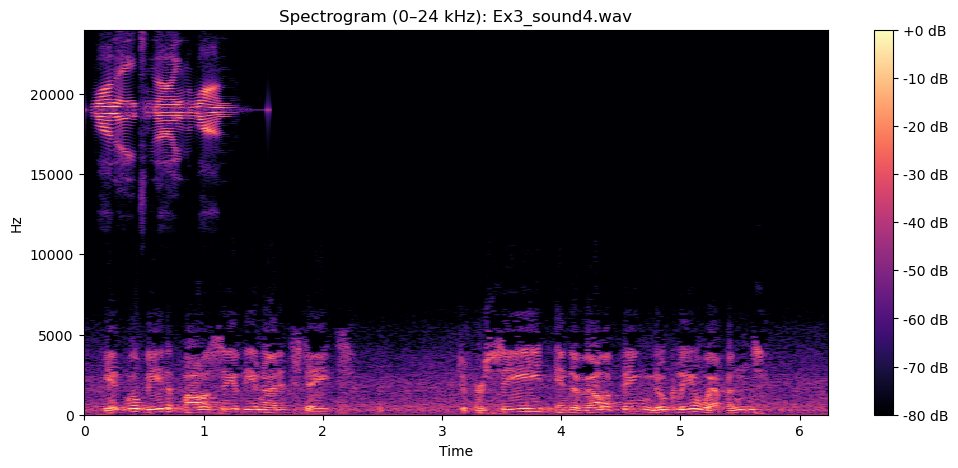

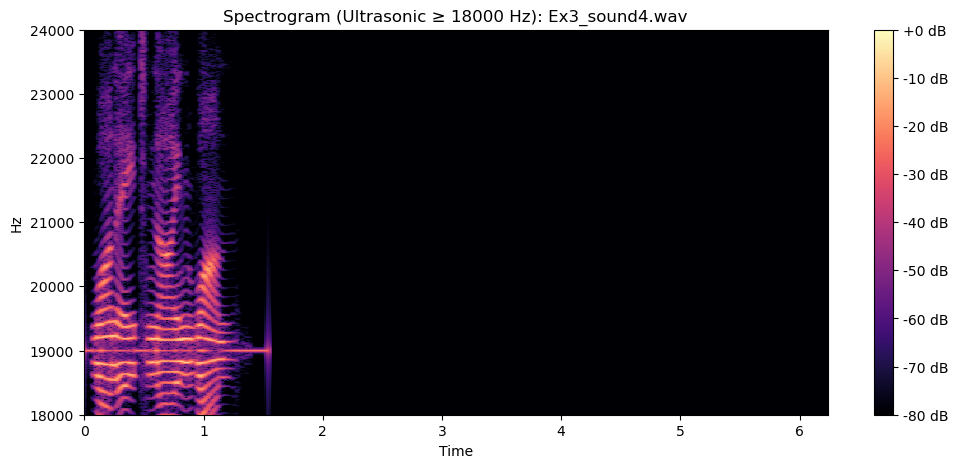

In [6]:
# -------------------------
# 3.1B) Spectrogram evidence (full band + ultrasonic zoom)
# -------------------------

# Loads the previously selected “most suspicious” file as a mono waveform for consistent spectral analysis.
y, sr = load_mono(suspicious_file, target_sr=None)

# Computes the Short-Time Fourier Transform so frequency content can be visualized over time.
# N_FFT controls frequency resolution, and HOP controls time resolution between frames.
S = librosa.stft(y, n_fft=N_FFT, hop_length=HOP, window="hann")

# Converts the magnitude spectrum into decibels, using the maximum value as the reference point.
# This makes weaker ultrasonic components easier to see alongside stronger audible content.
S_db = librosa.amplitude_to_db(np.abs(S), ref=np.max)

# Creates a wide spectrogram view showing the full audible range plus ultrasonic content up to 24 kHz.
plt.figure(figsize=(12, 5))
librosa.display.specshow(S_db, sr=sr, hop_length=HOP, x_axis="time", y_axis="hz")

# Sets the visible frequency range so the plot is limited to 0–24 kHz, but never exceeds Nyquist (sr/2).
plt.ylim([0, min(sr/2, 24000)])

# Adds a clear title indicating the displayed frequency band and the file being examined.
plt.title(f"Spectrogram (0–24 kHz): {os.path.basename(suspicious_file)}")

# Adds a decibel scale so the intensity of components can be compared visually.
plt.colorbar(format="%+2.0f dB")
plt.show()

# Creates a second spectrogram view focused only on the ultrasonic region for stronger evidence of carriers/encoding.
plt.figure(figsize=(12, 5))
librosa.display.specshow(S_db, sr=sr, hop_length=HOP, x_axis="time", y_axis="hz")

# Zooms the y-axis to the ultrasonic band starting at ULTRASONIC_LO, again respecting Nyquist and the 24 kHz cap.
plt.ylim([ULTRASONIC_LO, min(sr/2, 24000)])

# Adds a title that explicitly highlights the ultrasonic cutoff used for the zoomed inspection.
plt.title(f"Spectrogram (Ultrasonic ≥ {ULTRASONIC_LO} Hz): {os.path.basename(suspicious_file)}")

# Repeats the color scale for consistency so intensity comparisons remain meaningful in the zoomed view.
plt.colorbar(format="%+2.0f dB")
plt.show()


# Task 3.1 — Ultrasonic detection + AM demodulation

## Goal

Identify which suspicious file contains hidden ultrasonic content, then recover the hidden spoken code into the audible range.

## Method summary

1. Compute STFT for each suspicious file.
2. Measure energy inside the ultrasonic band (18–24 kHz, limited by Nyquist).
3. Rank files by ultrasonic-band energy and select the top candidate.
4. Produce spectrogram evidence (full band + ultrasonic zoom).
5. Estimate the ultrasonic peak (carrier) and demodulate using:
   - bandpass around the carrier
   - heterodyne (mix down) to baseband
   - lowpass to keep the recovered audible message
   - normalize and save output for playback


In [8]:
# -------------------------
# 3.1C) AM demodulate ultrasonic region -> audible playback
# -------------------------

# Estimates the dominant frequency component inside the ultrasonic band, treating it as the likely carrier.
# This provides the center frequency used for bandpass isolation and mixing down to baseband.
carrier = estimate_ultrasonic_peak_freq(y, sr, ULTRASONIC_LO, ULTRASONIC_HI, n_fft=N_FFT, hop=HOP)

# Stops immediately if no ultrasonic bins exist or no peak can be found (commonly due to low sample rate or no hidden signal).
if carrier is None:
    raise RuntimeError("No ultrasonic peak detected (sample rate too low or no ultrasonic content).")

# Logs the detected carrier frequency so the chosen demodulation target is visible and reportable.
print("Estimated ultrasonic carrier/peak (Hz):", carrier)

# Runs the demodulation pipeline:
# - bandpass around the carrier to isolate the suspected AM region
# - multiply by a cosine at the carrier frequency to shift the content to baseband
# - low-pass filter to keep the recovered audible-range message
# - normalize for clean playback
y_demod = am_demod_to_audible(y, sr, carrier_hz=carrier, bp_width=2500, audible_lp=4500)

# Defines the output path for the recovered message so it can be submitted and reused without re-processing.
demod_path = os.path.join(OUT_DIR, "ex3_1_demodulated_secret.wav")

# Saves the recovered waveform as 16-bit PCM WAV for broad compatibility and consistent playback.
save_wav_int16(demod_path, y_demod, sr)

# Confirms the save location in the notebook output to make it easy to locate the generated file.
print("Saved demodulated output:", demod_path)

# Plays the recovered audio directly in the notebook so the hidden spoken digits can be verified by listening.
display(Audio(y_demod, rate=sr))


Estimated ultrasonic carrier/peak (Hz): 19183.59375
Saved demodulated output: outputs/ex3_1_demodulated_secret.wav


# Task 3.2 — Embedding a hidden message (enhanced LSB) + extraction

## Goal

Embed the required secret message into `Ex3_sound5.wav` and extract it back to prove correctness.

## Enhancements beyond basic LSB

This implementation improves robustness and stealth by using:

- **Non-consecutive embedding** (seeded random distribution)
- **2 LSBs per sample** for higher capacity
- **Gap-preferring selection** (quiet samples preferred to reduce audible artifacts)
- **Payload scrambling** using XOR keystream (seeded)
- **Integrity verification** using CRC16
- **Key file saving** to ensure extraction uses identical indices and parameters every time


In [10]:
# ============================================================
# TASK 3.2 — Embedding hidden messages (FULL: start → end)
# Professional, robust, reproducible
#
# What you get:
# 1) Embed the REQUIRED secret message into Ex3_sound5.wav
# 2) More sophisticated than basic LSB:
#    - non-consecutive, seeded random distribution
#    - 2 LSBs per sample
#    - prefers “gaps” (near-zero amplitude) BUT works even if gaps are few
#    - payload scrambling (XOR keystream)
#    - integrity check (CRC16)
#    - key file saved so extraction ALWAYS uses identical indices
# 3) Extract the message back and VERIFY it matches exactly
#
# Outputs (inside ./outputs):
# - ex3_2_stego_sound5.wav
# - ex3_2_key.npz   (contains chosen indices + params)
# ============================================================

# ------------------------------------------------------------
#  Paths + required message
# ------------------------------------------------------------

# Uses the current working directory as the audio folder, matching a setup where the notebook is executed inside Ex3_files.
AUDIO_DIR = os.getcwd()  # you said your notebook runs inside Ex3_files already

# Builds an outputs directory path where generated audio and key files will be written.
OUT_DIR = os.path.join(AUDIO_DIR, "outputs")

# Creates the output folder if it does not exist so later saves do not fail.
os.makedirs(OUT_DIR, exist_ok=True)

# Defines the input carrier WAV used as the host signal that will receive the embedded payload.
CARRIER_WAV = os.path.join(AUDIO_DIR, "Ex3_sound5.wav")

# Defines where the stego WAV (carrier with embedded message) will be saved.
STEGO_WAV   = os.path.join(OUT_DIR, "ex3_2_stego_sound5.wav")

# Defines where the key/parameter bundle will be saved so extraction can reproduce identical embedding positions.
KEY_FILE    = os.path.join(OUT_DIR, "ex3_2_key.npz")

# Stores the required secret text payload exactly as specified for the task.
SECRET_MESSAGE = "It always seems impossible until it's done"

# Verifies the carrier WAV exists before attempting any read/processing.
if not os.path.isfile(CARRIER_WAV):
    raise FileNotFoundError(f"Missing carrier file: {CARRIER_WAV}")

# Confirms the cell completed successfully and prints absolute paths for quick verification and debugging.
print("Cell OK")
print("Carrier:", os.path.abspath(CARRIER_WAV))
print("Out dir:", os.path.abspath(OUT_DIR))


Cell OK
Carrier: /Users/paris/Desktop/vosk/audio_files/Ex3_files/Ex3_sound5.wav
Out dir: /Users/paris/Desktop/vosk/audio_files/Ex3_files/outputs


## 3.2 Helpers — bit encoding, stable header, scrambling, CRC

To embed text inside audio samples, the message must be converted into a bitstream. This section defines utilities for:

- Converting **text ↔ bits** safely using UTF-8 encoding
- Encoding/decoding **32-bit integers ↔ bits** in little-endian format (for a stable header)
- Computing a simple **CRC16** checksum for integrity checking
- Scrambling/descrambling payload bits using **XOR with a deterministic keystream** derived from a seed

### Payload format

The embedded bitstream is structured as:

- **Header (64 bits):**
  - 32-bit payload length (bits)
  - 32-bit CRC field (CRC16 stored inside)
- **Payload:**
  - scrambled message bits


In [12]:
# ------------------------------------------------------------
#  Helpers (bits, CRC, scrambling, stable header)
# ------------------------------------------------------------

# Converts a UTF-8 string into a flat array of 0/1 bits.
# The text is encoded into bytes, then unpacked so each byte becomes 8 individual bits.
def text_to_bits(s: str) -> np.ndarray:
    b = s.encode("utf-8")
    return np.unpackbits(np.frombuffer(b, dtype=np.uint8)).astype(np.uint8)

# Converts an array of bits back into a UTF-8 string.
# If the bit-count is not a multiple of 8, the tail is padded so bytes can be reconstructed safely.
def bits_to_text(bits: np.ndarray) -> str:
    bits = np.asarray(bits, dtype=np.uint8)
    if bits.size % 8 != 0:
        bits = np.pad(bits, (0, 8 - (bits.size % 8)))
    return np.packbits(bits).tobytes().decode("utf-8", errors="strict")

# Encodes a 32-bit unsigned integer into bits using little-endian byte order.
# This is typically used for stable headers such as payload length or seed values.
def u32_to_bits_le(n: int) -> np.ndarray:
    n = int(n) & 0xFFFFFFFF
    b = n.to_bytes(4, byteorder="little", signed=False)
    return np.unpackbits(np.frombuffer(b, dtype=np.uint8)).astype(np.uint8)

# Decodes a 32-bit little-endian bit sequence back into an unsigned integer.
# Bits are reshaped into 4 bytes, packed into uint8 values, then interpreted as little-endian.
def bits_to_u32_le(bits32: np.ndarray) -> int:
    bits32 = np.asarray(bits32, dtype=np.uint8).reshape(4, 8)
    b = np.packbits(bits32, axis=1).flatten().astype(np.uint8)
    return int.from_bytes(bytes(b.tolist()), byteorder="little", signed=False)

# Computes a compact CRC16-style checksum over a bit array.
# This gives a quick integrity signal so extraction can detect wrong keys or corrupted payload bits.
def simple_crc16(bits: np.ndarray) -> int:
    # lightweight, fine for coursework verification
    acc = 0xBEEF
    for v in bits.astype(np.uint8):
        acc = ((acc << 1) ^ (0x1021 if (acc & 0x8000) else 0)) & 0xFFFF
        acc ^= int(v)
    return acc & 0xFFFF

# Scrambles (or descrambles) a bitstream using XOR against a deterministic pseudorandom keystream.
# Using the same seed regenerates the same keystream, allowing reversible masking during extraction.
def xor_bits(bits: np.ndarray, seed: int) -> np.ndarray:
    rng = np.random.default_rng(int(seed))
    ks = rng.integers(0, 2, size=bits.size, dtype=np.uint8)
    return (bits.astype(np.uint8) ^ ks).astype(np.uint8)

# Confirms the helper utilities are defined and ready for the embedding/extraction stages.
print(" Cell OK")


 Cell OK


## 3.2 Core — index selection and LSB embedding

### Index selection (gap-preferring, seeded)

Embedding positions are chosen by:

- Detecting “gaps” (near-zero amplitude samples)
- Using a fraction cap to avoid embedding only in early silence
- Shuffling candidate indices using a fixed seed for reproducibility
- Falling back to using the full signal if quiet samples are insufficient

### Embedding method (2 LSBs per sample)

At each chosen index, the lowest `LSB_BITS` are cleared and replaced with the next payload bits. The audio length stays identical; only small numeric changes occur in selected samples.


In [14]:
# ------------------------------------------------------------
#  Core: choose indices (gap-preferring, stable) + embed
# ------------------------------------------------------------

# Loads a WAV file and returns a mono int16 signal along with its sample rate.
# If the file is stereo, only the first channel is used to keep embedding consistent and predictable.
# Any non-int16 formats are converted into int16 so LSB operations behave exactly as intended.
def load_int16_mono(wav_path: str):
    sr, x = wavfile.read(wav_path)
    if x.ndim == 2:
        x = x[:, 0]
    if x.dtype != np.int16:
        if np.issubdtype(x.dtype, np.floating):
            x = np.clip(x, -1.0, 1.0)
            x = (x * 32767.0).astype(np.int16)
        else:
            x = np.clip(x.astype(np.float32), -32768, 32767).astype(np.int16)
    return int(sr), x

# Selects sample indices where bits will be embedded.
# The selection aims to prefer low-amplitude “gaps” (near silence) to reduce audible artifacts.
# A seeded RNG is used so the same seed always produces the same randomized distribution.
def select_indices_gap_preferring(
    x_int16: np.ndarray,
    total_bits: int,
    lsb_bits: int,
    seed: int,
    gap_threshold: float,
    max_gap_fraction: float
):
    # Computes how many audio samples are required to store the payload when using lsb_bits per sample.
    # Example: with 2 LSBs per sample, 100 bits needs 50 samples.
    samples_needed = int(np.ceil(total_bits / lsb_bits))

    # Converts int16 samples into normalized float range so a simple amplitude threshold can find “quiet” regions.
    xf = x_int16.astype(np.float32) / 32768.0

    # Identifies indices where the absolute amplitude is below the gap threshold, treated as low-risk embedding points.
    gap_idx = np.where(np.abs(xf) <= float(gap_threshold))[0]

    # If gaps exist, trims the usable gap pool so embedding does not cluster only in the earliest silence.
    # This keeps the embedding locations distributed in a more natural way across the signal.
    if gap_idx.size > 0:
        gap_idx = gap_idx[: int(gap_idx.size * float(max_gap_fraction))]

    # Initializes a deterministic random generator so the shuffled index order can be reproduced during extraction.
    rng = np.random.default_rng(int(seed))

    # Chooses the candidate pool:
    # - If there are enough quiet samples, embed only within that gap set.
    # - Otherwise, fall back to using the full signal so embedding still succeeds.
    if gap_idx.size >= samples_needed:
        candidate = gap_idx.copy()
        used_gaps = True
    else:
        candidate = np.arange(x_int16.size, dtype=np.int64)
        used_gaps = False

    # Randomizes the candidate index order, then selects the first samples_needed positions.
    rng.shuffle(candidate)

    # Sorts the final chosen indices so embedding happens in ascending sample order, making it stable and easier to debug.
    chosen = np.sort(candidate[:samples_needed].astype(np.int64))
    return chosen, used_gaps, int(samples_needed)

# Embeds a bitstream into the least significant bits of selected samples.
# The function clears the target LSB region first, then writes lsb_bits bits per chosen sample.
def embed_lsb_at_indices(x_int16: np.ndarray, indices: np.ndarray, bits: np.ndarray, lsb_bits: int):
    # Copies the original audio so embedding does not modify the input array in-place.
    x_out = x_int16.copy()

    # Builds a mask that targets only the lowest lsb_bits, for example lsb_bits=2 -> mask=0b11.
    mask = (1 << int(lsb_bits)) - 1

    # Builds an inverse mask so the LSB region can be cleared while preserving all higher bits.
    clear_mask = ~mask

    # Tracks the global position within the payload bit array.
    k = 0

    # Iterates through the chosen sample indices and packs up to lsb_bits bits into each sample.
    for s_i in indices:
        # Accumulates the replacement LSB value that will be written into the current sample.
        v = 0

        # Fills the LSB region bit-by-bit from the payload, stopping if the payload runs out.
        for b in range(int(lsb_bits)):
            if k < bits.size:
                v |= (int(bits[k]) & 1) << b
                k += 1

        # Clears the existing LSB region and inserts the new packed bits while leaving the rest of the sample unchanged.
        x_out[s_i] = (x_out[s_i] & clear_mask) | v

    # Verifies that all payload bits were embedded; if not, the carrier lacked capacity for the chosen settings.
    if k < bits.size:
        raise RuntimeError("Embedding failed: insufficient capacity.")
    return x_out

# Confirms the embedding utilities are defined and ready to be used by the next stage.
print(" Cell OK")


 Cell OK


In [15]:
# Read carrier as int16 mono
# Loads the carrier WAV file and returns:
# - sr: the sample rate in Hz
# - x_int16: a 1D mono waveform as signed 16-bit integers (the raw sample array)
sr, x_int16 = load_int16_mono(CARRIER_WAV)

# Prints basic metadata so the array size and sampling frequency are visible immediately.
print("Sample rate:", sr)
print("Total samples:", x_int16.size)

# Print first 200 samples (raw int16)
# Shows a small slice of the waveform array rather than printing the full signal (which is usually very large).
# These values are the actual PCM sample amplitudes stored in the WAV file.
print("\nFirst 200 samples (int16):")
print(x_int16[:200])



Sample rate: 44100
Total samples: 407280

First 200 samples (int16):
[  1   0   1   0   1   0  -1  -2  -3  -5  -4  -3  -1   2   4   7   6   3
   1  -2  -5  -7  -8  -7  -4  -1   2   5   5   5   3   0  -1  -2  -1   1
   3   6   8   9   8   8   4   3   3   3   5  10  14  19  21  21  17  11
   2  -8 -16 -24 -28 -29 -28 -23 -17 -10  -4   1   6   8  12  14  15  14
  13  11   7   4   1  -1  -1   0   5  11  17  23  27  29  29  28  25  22
  20  17  15  13  10   6   1  -2  -6  -7  -4   1   9  18  25  28  25  17
   5  -7 -18 -24 -24 -16  -2  13  28  40  46  46  41  32  23  15   9   7
   8  10  14  19  24  30  35  39  43  45  46  45  42  38  33  29  24  19
  15  10   5   2   1   4  10  19  29  36  40  37  29  16   0 -14 -25 -32
 -34 -32 -28 -23 -18 -13  -7   0   7  16  24  29  29  24  15   4  -5 -10
 -11  -6   1  10  16  20  19  17  16  16  19  24  27  28  23  13   0 -12
 -20 -21]


/var/folders/fc/ptw8y0k116ng1nzcdc190hvc0000gn/T/ipykernel_85120/4090028643.py:9: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr, x = wavfile.read(wav_path)


## 3.2 Cell 4 — Embed the payload and save the key

This section performs the complete embedding pipeline:

1. Convert message to bits.
2. Compute payload length and CRC16.
3. Scramble payload using XOR keystream.
4. Build `full_bits = header + scrambled_payload`.
5. Select embedding indices (gap-preferring, seeded).
6. Embed into the carrier using 2 LSBs per sample.
7. Save:
   - stego WAV file (`ex3_2_stego_sound5.wav`)
   - key file (`ex3_2_key.npz`) containing parameters and exact indices




In [17]:
# ------------------------------------------------------------
#  Run embedding (writes stego + saves key)
# ------------------------------------------------------------

# Fixed seed used for all randomized steps so the embedding pattern is reproducible.
# Using the same seed later allows identical scrambling and consistent index selection.
SEED = 2026

# Number of least-significant bits written per audio sample.
# With 2 bits per sample, the payload capacity doubles compared to 1-bit LSB embedding.
LSB_BITS = 2

# Normalized amplitude threshold used to define “gap” samples (near silence).
# Samples with absolute amplitude below this value are treated as safer embedding candidates.
GAP_THRESHOLD = 0.0025

# Fraction of gap indices allowed into the candidate pool.
# This prevents the algorithm from embedding only in the earliest silent region and helps spread changes out.
MAX_GAP_FRACTION = 0.85

# Loads the carrier WAV as a mono int16 waveform so bit-level LSB edits behave predictably.
# sr is the sample rate in Hz, x is the raw PCM sample array.
sr, x = load_int16_mono(CARRIER_WAV)

# Converts the secret message string into a flat array of 0/1 bits suitable for LSB embedding.
payload_bits = text_to_bits(SECRET_MESSAGE)

# Stores the payload bit-length explicitly for the header so extraction knows exactly how many bits to recover.
msg_len_bits = int(payload_bits.size)

# Computes an integrity checksum over the original (unscrambled) payload bits.
# This is used later to verify extraction correctness and detect wrong keys or corruption.
crc16 = simple_crc16(payload_bits)

# Scrambles the payload bits using XOR with a deterministic pseudorandom keystream derived from SEED.
# This makes the embedded bit pattern less readable even if someone extracts raw LSBs without the correct seed.
payload_scrambled = xor_bits(payload_bits, SEED)

# Creates a stable header so extraction can be self-contained:
# - first 32 bits store the payload length (in bits)
# - next 32 bits store the CRC16 value (placed inside a 32-bit little-endian field)
header_len = u32_to_bits_le(msg_len_bits)
header_crc = u32_to_bits_le(crc16)  # crc stored in 32-bit field

# Builds the full bitstream to embed: header (length + crc) followed by the scrambled payload.
# Everything is cast to uint8 to keep bit operations clean and consistent.
full_bits = np.concatenate([header_len, header_crc, payload_scrambled]).astype(np.uint8)

# Chooses which sample indices will carry the hidden bits:
# - prefers low-amplitude “gap” samples when enough are available
# - otherwise falls back to sampling across the whole signal
# - shuffles the candidate pool using SEED to distribute embedding positions non-consecutively
chosen_idx, used_gaps, samples_needed = select_indices_gap_preferring(
    x_int16=x,
    total_bits=int(full_bits.size),
    lsb_bits=LSB_BITS,
    seed=SEED,
    gap_threshold=GAP_THRESHOLD,
    max_gap_fraction=MAX_GAP_FRACTION
)

# Embeds the full bitstream into the carrier by overwriting the lowest LSB_BITS bits at each chosen sample index.
# The carrier length remains unchanged; only small numeric changes occur in selected samples.
x_stego = embed_lsb_at_indices(x, chosen_idx, full_bits, LSB_BITS)

# Writes the modified waveform out as a new WAV file that contains the hidden message.
# The stored dtype is enforced as int16 so the output is standard PCM audio.
wavfile.write(STEGO_WAV, sr, x_stego.astype(np.int16))

# Saves the exact embedding parameters and the exact chosen indices into a key file.
# This guarantees extraction does not depend on re-running selection logic and avoids any mismatch or “drift”.
np.savez(
    KEY_FILE,
    seed=int(SEED),
    lsb_bits=int(LSB_BITS),
    gap_threshold=float(GAP_THRESHOLD),
    max_gap_fraction=float(MAX_GAP_FRACTION),
    msg_len_bits=int(msg_len_bits),
    crc16=int(crc16),
    chosen_idx=chosen_idx
)

# Confirms embedding has completed and prints a summary of what was embedded and where it was saved.
print("Cell OK")
print("Embedding complete:")
print({
    "sr": sr,
    "msg_len_bits": msg_len_bits,
    "crc16": crc16,
    "total_bits": int(full_bits.size),
    "samples_needed": samples_needed,
    "used_gap_samples": bool(used_gaps),
    "output": os.path.relpath(STEGO_WAV, AUDIO_DIR),
    "key": os.path.relpath(KEY_FILE, AUDIO_DIR),
})

# Prints an absolute path so the generated stego file can be located directly on disk.
print("Stego file saved to:", os.path.abspath(STEGO_WAV))


Cell OK
Embedding complete:
{'sr': 44100, 'msg_len_bits': 336, 'crc16': 8644, 'total_bits': 400, 'samples_needed': 200, 'used_gap_samples': True, 'output': 'outputs/ex3_2_stego_sound5.wav', 'key': 'outputs/ex3_2_key.npz'}
Stego file saved to: /Users/paris/Desktop/vosk/audio_files/Ex3_files/outputs/ex3_2_stego_sound5.wav


/var/folders/fc/ptw8y0k116ng1nzcdc190hvc0000gn/T/ipykernel_85120/4090028643.py:9: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr, x = wavfile.read(wav_path)


## 3.2 Cell 5 — Extract using saved key and verify correctness

Extraction is designed to be stable by using the saved key file:

1. Load seed, LSB settings, message length, CRC, and exact chosen indices.
2. Read the embedded bits from the stego WAV at those indices.
3. Parse the 64-bit header (length + CRC).
4. Validate header matches the key file values.
5. Descramble payload using the seed.
6. Recompute CRC16 and compare.
7. Decode bits back to UTF-8 text.
8. Verify the extracted message matches the required secret exactly.

### Evidence to capture (screenshots)
- Extraction header output (length + CRC)
- CRC check (stored vs computed)
- Extracted message output
- Final verification confirmation


In [19]:
# ------------------------------------------------------------
#  Extract using the saved key (guaranteed stable) + verify
# ------------------------------------------------------------

# Reads embedded bits back out of an int16 audio array by sampling specific indices
# and unpacking the lowest lsb_bits from each selected sample into a flat bitstream.
def read_lsb_bits_at_indices(x_int16: np.ndarray, indices: np.ndarray, total_bits: int, lsb_bits: int) -> np.ndarray:
    # Mask that isolates only the lowest lsb_bits of a sample (e.g., lsb_bits=2 -> mask=0b11).
    mask = (1 << int(lsb_bits)) - 1

    # Preallocates an output array to store the exact number of bits requested.
    out = np.empty(int(total_bits), dtype=np.uint8)

    # Tracks the current write position in the output bit array.
    k = 0

    # Iterates through the same sample indices used during embedding.
    for s_i in indices:
        # Extracts the low bits from the current sample using the mask.
        v = int(x_int16[s_i]) & mask

        # Unpacks those low bits into individual 0/1 values, preserving the same bit order used in embedding.
        for b in range(int(lsb_bits)):
            if k < out.size:
                out[k] = (v >> b) & 1
                k += 1
            else:
                break

        # Stops early once the requested number of bits has been collected.
        if k >= out.size:
            break

    # Returns the recovered bitstream (header + payload bits).
    return out

# Confirms the stego audio file exists before attempting to extract.
if not os.path.isfile(STEGO_WAV):
    raise FileNotFoundError(f"Missing stego file: {STEGO_WAV}")

# Confirms the key file exists so extraction uses the exact parameters and indices from embedding.
if not os.path.isfile(KEY_FILE):
    raise FileNotFoundError(f"Missing key file: {KEY_FILE}")

# Loads the saved key bundle that contains the embedding settings and the exact chosen sample indices.
key = np.load(KEY_FILE, allow_pickle=False)

# Reads core parameters from the key file so extraction matches embedding exactly.
seed_k = int(key["seed"])
lsb_k  = int(key["lsb_bits"])
msg_k  = int(key["msg_len_bits"])

# Reads the stored CRC value, clamping to 16 bits since CRC16 is the intended width.
crc_k  = int(key["crc16"]) & 0xFFFF

# Reads the exact sample indices used during embedding, ensuring type is stable for indexing.
idx_k  = key["chosen_idx"].astype(np.int64)

# Loads the stego WAV as mono int16 so LSB extraction behaves predictably.
sr2, x2 = load_int16_mono(STEGO_WAV)

# Total bits expected during extraction:
# 64 bits for the header (32-bit length + 32-bit CRC field) plus the payload length in bits.
TOTAL_BITS = 64 + msg_k

# Extracts the raw embedded bits from the stego signal using the saved indices and saved LSB width.
bits_raw = read_lsb_bits_at_indices(x2, idx_k, TOTAL_BITS, lsb_k)

# -------------------------
# Header parsing (length + CRC)
# -------------------------

# Reads the first 32 bits as the payload length (little-endian), allowing extraction to validate sizing.
msg_len_h = bits_to_u32_le(bits_raw[:32])

# Reads the next 32 bits as the CRC field, then clamps to 16 bits to compare CRC16 values.
crc_h     = bits_to_u32_le(bits_raw[32:64]) & 0xFFFF

# Prints the header information to make the extraction traceable for reporting and debugging.
print("Extraction header:")
print(" - sample rate:", sr2)
print(" - payload length (bits):", msg_len_h)
print(" - stored CRC16:", crc_h)

# Sanity checks to ensure the key and stego file actually match:
# If these fail, the wrong key file or wrong stego audio was likely used.
assert msg_len_h == msg_k, "❌ Header length mismatch (wrong key/stego pair)."
assert crc_h == crc_k, "❌ Header CRC mismatch (wrong key/stego pair)."

# -------------------------
# Payload recovery (descramble + CRC verify + decode)
# -------------------------

# Extracts the payload portion only (everything after the 64-bit header).
payload_scr = bits_raw[64:64 + msg_k]

# Descrambles the payload by applying the same XOR keystream (same operation as scrambling).
# XOR is reversible, so running it again with the same seed restores the original payload bits.
payload = xor_bits(payload_scr, seed_k)

# Recomputes the CRC16 over the recovered payload bits to verify data integrity.
crc_calc = simple_crc16(payload) & 0xFFFF

# Prints integrity results so it is clear whether recovery was clean and correct.
print("\nCRC check:")
print(" - stored:", crc_k)
print(" - computed:", crc_calc)

# Fails if the recovered payload does not match the stored checksum, indicating corruption or wrong parameters.
assert crc_calc == crc_k, "❌ CRC mismatch (data integrity failed)."

# Converts the verified payload bitstream back into the original UTF-8 message.
message_out = bits_to_text(payload)

# Displays the recovered message so it can be compared directly with the expected secret.
print("\n✅ Extracted message:\n", message_out)

# Coursework verification step: ensures the extracted message matches the required message exactly.
assert message_out == SECRET_MESSAGE, "❌ Extracted message does NOT match required secret message!"
print("\n✅ VERIFIED: extracted message matches exactly and CRC is valid.")


Extraction header:
 - sample rate: 44100
 - payload length (bits): 336
 - stored CRC16: 8644

CRC check:
 - stored: 8644
 - computed: 8644

✅ Extracted message:
 It always seems impossible until it's done

✅ VERIFIED: extracted message matches exactly and CRC is valid.


# Outputs produced

**Task 3.1**
- Ranking output (ultrasonic anomaly detection)
- Spectrogram evidence (full band + ultrasonic zoom)
- Demodulated audio saved in `outputs/` for playback

**Task 3.2**
- `outputs/ex3_2_stego_sound5.wav`
- `outputs/ex3_2_key.npz`

These files provide evidence that the hidden code was recovered (Task 3.1) and that message embedding + extraction works correctly with integrity checks (Task 3.2).
